`process_execute`
   Copies the command line into a page, allocates a `child_record` with
   `ref_cnt` set to 2, creates a thread, then waits on `loaded` for the child to
   report back. It adds the record to the list only if the child succeeds. 


   ...
   ... spawn a new kernel thread to run a user program while synchronising with
   that child until its executable binary finishes loading into memory. It
   first copies `cmd_line` into a freshly

`tid_t process_execute (const char *cmd_line)`
   Creates and starts a new process to run the user program specified from
   the input command-line string `cmd_line`, returning the tid of the thread 
   running the new process. 

   ... the manual's own description of `pagedir.c` says "you probably won't want
   to modify this code for this task, you may want to call some of its functions
   " ... 

   ... you will enable programs to interact with the OS via system calls. 

   You will be working out of the `userprog` directory ... ...

   ... all the test code from the last assignment ran as part of the kernel, 
   with full access to priviledged parts of the system. Once we start running
   user programs on top of the OS ... this is no longer true ... this
   task deals with the consequences

   we allow more than one process to run at a time. Each process has one thread
   (multi-threaded processes are not supported) ... must manage memory, 
   scheduling, and other state correctly to maintain this illustion
   > User programs are written under the illustion that they have the entire
   > machine. 

   In the previous task, we compiled our test code directly ... test your OS
   by running user programs ... must make sure that the user program interface
   meets the specifications described here, but given that constraint
   you are free to ... 

   CONSTRAINT: == make sure that the user program interface meets the
   specifications described here ... 


---


'process.ch'
   Basic user process support, including loading ELF binaries into memory.
   `process.h` defines `struct process`, which you are likely to modify in the
   last two weeks. 

pagedir.ch
   A simpler maanger for 80x86 hardware page tables

syscall.ch
   Whenever a user process wants to access some kernel functionality... it
   invokes a system call. This is a skeleton system call handler. Currently,
   it just prints a message and terminates the user process. 



   ...
```c
bool load (const char *file_name, void (**eip)(void), void **esp)
```

HOW `load()` WORKS IN PINTOS
   When a user process starts via `start_process ()`, ... it calls 

   - ... ALLOCATES A PAGE DIRECTORY ... calls `pagedir_create ()` to give the
     new user process its own isolated virtual address space ... 


        ```
        just know internally that start_process () itself is invoked whenever a new thread is scheduled after it's initial creationg from thread_create ()
        ```

```c
// A thread function that loads a user process and starts running it... 
start_process (void *args_)
    -> (process.c:287)
// to prepare the ELF executable for the CPU... 
load (args->cmd_line, &if_.eip, &if_.esp);   <--// if stands for interrupt frame
        -> (process.c:598) 
        // give new user process its own isolated virtual address space
        cur->pagedir = pagedir_create ();        
        
        -> (process.c:628-683)
        // Loads program segments... Loops through the program header table
        // `struct Elf32_Phdr phdr;` ... for each loadable segment
        switch (phdr.p_type)
          {
            ...
            case PT_LOAD:
              load_segment (...);       // line 675
            ...
          }

        -> (process.c:686)
        // SETS UP THE USER STACK. Calls `setup_stack ()` to allocate a zeroed
        // page at `PHYS_BASE` and sets the initial stack pointer (`*esp`)
        setup_stack (esp)

        -> (process.c:690)
        // SETS ENTRY POINT ... tells the CPU the exact memory address where
        // execution should begin when switching to user mode ... 
        *eip = (void (*) (void)) ehdr.e_entry;




```

-- LOADS PROGRAM SEGMENTS. Loop through the Program Header 

   ... you probably won't want to modify this code for this task, you may want
   to call some of its functions ... 

TASK 2 OVERVIEW, CITED
   1. User virtual memory runs from virtual `0x00000000` up to 
      virtual address `PHYS_BASE = 0xc0000000` ... Kernel virtual memory is 
      everything above it ... User memory is per process and kernel memory is 
      global ... 
   2. When the kernel switches process it switches page directory with 
      `pagedir_activate()` ... The base code already calls create, destry and
      activate for you ... 





   ... notably, `malloc ()` cannot be implemented because none of the 
   sys-calls (system calls) required for this task allows for memory allocation
   ... PintOS also can't run programs that use FP ops ... since the kernel
   doesn't save and restore the processor's FP unit when switching
   threads ... 

   ... until you copy a test program to the simulated file system, PintOS 
   will be unable to do useful work. You won't be able to do interesting things
   until yoyu copy a variety of programs to the file system. ... 

---
4.1.4 VIRTUAL MEMORY LAYOUT ... 
   ... virutal memory in PintoS is divided into two regions ... user virtual
   memory and kernel virtual memory ... 

   In Pintos, `pd` in `pagedir_activate (uint32_t *pd)`... stands for 
   PAGE DIRECTORY... a pointer to a 4KB array of 32-bit entries (directory 
   entries)... that maps a process' virtual address to physical memory frames .. 


How `pagedir_activate ()` works
   - PURPOSE. it makes `pd` the page table the CPU uses to translate addresses ... 

   ...
   ```
    Stores the physical address of the page directory into CR3 (or the PDBR
    = page directory base register) ... This activates the new page tables
    immediately ... 
   ```

```c

/* Sets up the CPU for running user code in the current thread.
   This function is called on every context switch. */
void
process_activate (void)
{
  struct process *cur = thread_current ()->process;
  
  /* Activate thread's page tables if running an active process. */
  if (cur != NULL)  
    pagedir_activate (cur->pagedir);            // <-- Points CPU's PDBR to thread_current ()->process->pagedir pointer!

  /* Set thread's kernel stack for use in processing
     interrupts. */
  tss_update ();
}

```




```c
static inline bool
is_user_vaddr (const void *vaddr)
   // Returns true for a user virtual address. It is named as one of the 
   // two functions for checking pointers ... 

void *
pagedir_get_page (uint32_t *pd, const void *uaddr)
   // Returns the kernel virtual address of the frame or a null pointer if 
   // unmapped... 
   // < -- RETURNS VIRTUAL ADDRESS IN KERNEL SPACE (above `PHYS_BASE`), not
   // a raw physical RAM address
      // see this -> 
      return pte_get_page (*pte) + pg_ofs (uaddr);
            /* Returns a pointer to the page that page table entry PTE points
               to. */
            static inline void *pte_get_page (uint32_t pte) {
               return ptov (pte & PTE_ADDR);
            }
                  // look at the definition of ptov and PTE_ADDR which is just 0xfffff000

```

WHY THE KERNEL NEEDS IT
   The kernel reads and writes memory that a user program points to. A user
   pointer is just a number chosen by the program... can be NULL, a kernel
   address such as virtual `0xc0000000` ... or a virtual page with no frame
   behind it... 
   
   If the kernel uses an unmapped virtual page ... a page fault happens in
   kernel mode and PintOS panics ... 

   A virtual page is "mapped" when the process's hardware page 

---
      A virtual page is "mapped" when the process's hardware page table has a valid entry linking that virtual address to an actual frame of physical RAM, with its "present" bit set to 1. When any code tries to read or write an unmapped virtual address, the CPU's memory management unit cannot find a physical RAM location and immediately triggers a hardware page fault exception.


---
      Your guess is right on the money: PintOS operates on the strict assumption that kernel code is bug-free and only ever dereferences valid memory. Because of this guarantee, page_fault() in exception.c treats any fault triggered while executing in kernel mode (SEL_KCSEG) as a fatal OS bug and immediately calls PANIC() to crash the entire machine. Even worse, if the kernel crashes mid-syscall after acquiring a lock or allocating memory, it leaks those resources and leaves downstream kernel structures in a permanently broken or deadlocked state. By verifying that user pointers are mapped before the kernel touches them, you catch bad addresses early and cleanly terminate just the offending user process instead of letting it trick the kernel into panicking the whole OS.


---
      ```sh
      ❯ okay so should the mental model in e just be this is important later, and just stop letting the ptov bug me?

      Yes. Think of pagedir_get_page () as answering two questions:

      1. Is this virtual page mapped to a frame? The NULL check answers this, and safemem only uses this answer.
      2. If it is mapped, where can the kernel access the frame? ptov () gives this answer. Task 2 does not use it.
      ```

THREAD VS PROCESS
    the end goal is to cook pasta. but we have two things in parallel, chef A boils pasta, chef B preps the puree sauce

    so is the thread each chef? (worker?)

    whilst the process is the whole process from start (raw ingreidents)... all the way to the end ogal?

# In PintOS, 1 program == 1 process
    ## A program only becomes multiple processes if it explicitl uses the 
    ## `exec` system call to launch a completely separate and new program
    ## in its isolated memory space ... 

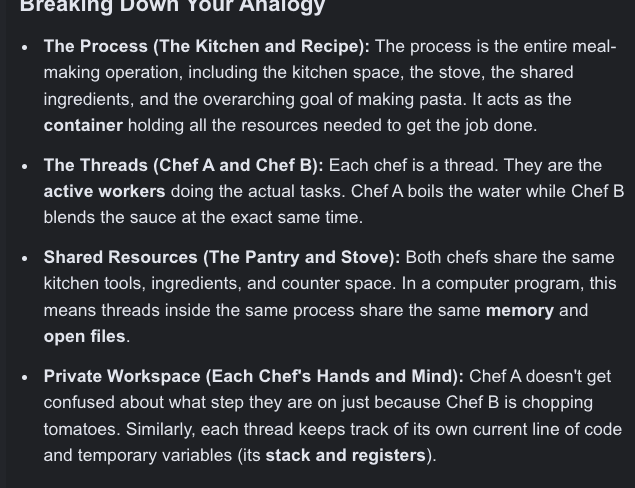

```c
lookup_page (uint32_t *pd, const void *vaddr, bool create)
   ...
   /*
   Returns the address of the page table entry for virtual address VADDR in 
   page directory PD...

   If PD does not have a page table for VADDR... .... create new table if 
   `bool create` is true, else just returns NULL ptr
   */


```

Time: 35 min
Topic: Argument passing
Manual (printed pp.): 4.3.3 (p33), 4.5.1 Program Startup (p40–41), 4.4.1 FAQ (p39)
Team code to read: process.c:270-390 (start_process tail, split_words, push, push_arguments), setup_stack at :821 (sm4925)
Grid rows it covers: Correct argument passing, no limits, abstraction, memory efficiency

```c
static inline bool
is_user_vaddr (const void *vaddr)
   // Returns true for a user virtual address. It is named as one of the 
   // two functions for checking pointers ... 

void *
pagedir_get_page (uint32_t *pd, const void *uaddr)
   // Returns the kernel virtual address of the frame or a null pointer if 
   // unmapped... 



```

# TDL

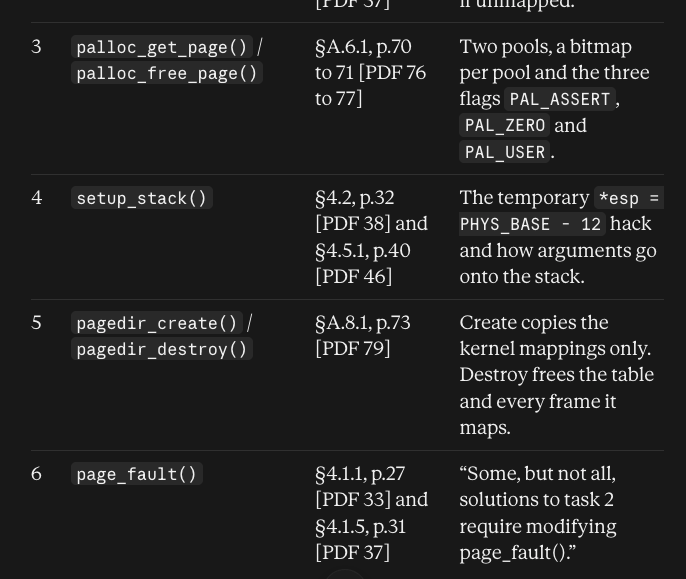

```sh
#: 1
Time: 35 min
Topic: Argument passing
Manual (printed pp.): 4.3.3 (p33), 4.5.1 Program Startup (p40–41), 4.4.1 FAQ (p39)
Team code to read: process.c:270-390 (start_process tail, split_words, push, push_arguments), setup_stack at :821 (sm4925)
Grid rows it covers: Correct argument passing, no limits, abstraction, memory efficiency
────────────────────────────────────────
#: 2
Time: 40 min
Topic: Syscall entry and safe user memory
Manual (printed pp.): 4.5.2 System Call Details (p41), 4.1.5 Accessing User Memory (p30–32), A.7 Virtual Addresses (p72), A.8.2 Inspection (p74)
Team code to read: syscall.c:1-103 (dispatch table, handler), all of safemem.c (syl25, st3125)
Grid rows it covers: Abstracted handler, abstracted memory checks
────────────────────────────────────────
#: 3
Time: 50 min
Topic: exec / wait / exit lifecycle
Manual (printed pp.): 4.3.2 Termination Messages (p33), exec/wait/exit in 4.3.4 (p34–35), A.3 Processes (p61–62), A.4.2–A.4.3 Semaphores and
  Locks (p63–64)
Team code to read: process.h, process.c:1-143 (child_record, process_execute), :237-269 process_init, :392-500 wait, release, exit (sm4925,
  st3125)
Grid rows it covers: Encapsulation, wait/exit races, no global sync, memory leaks (2 marks), efficient storage, child load success
────────────────────────────────────────
#: 4
Time: 35 min
Topic: fd table and file syscalls
Manual (printed pp.): Rest of 4.3.4 (p35–37), 4.3.5 Denying Writes (p37), 4.4.2 FAQ (p39–40), A.10.1–A.10.5 Hash Table (p82–87)
Team code to read: process.c:145-236 fd helpers (syl25), syscall.c:145-322 (your code, so skim), file_deny_write at process.c:611
Grid rows it covers: Thread-safe fd storage, processes and filesystem kept separate
────────────────────────────────────────
#: 5
Time: 20 min
Topic: Self-test
Manual (printed pp.): Marking grid parts 1–3
Team code to read: Your answers
Grid rows it covers: All
```

-- PAGE DIRECTORY -> PAGE TABLE -> PHYSICAL PAGE (Frame)


-- PAGE DIRECTORY -> PAGE TABLE -> PHYSICAL PAGE (Frame)




-- An ELF (Executable and Linkable Format) is the standard binary file format
   used for executables, object code, shared libraries, and core dumps on 
   Linux and Unix-like operating systems... 

   - RUNS PROGRAMS
   - STORES CODE AND DATA
   - SUPPORTS LIBRARIES .... 

-- `strspn (const char *string, const char *skip)`
   RETURNS the index of the first char in STRING which character isn't inside 
   SKIP

-- `strchr (skip, c)` asks whether `c` is in the set. `NULL` means it is not, 
   <-- basically, it just checks whether is `c` inside of `skip`. that's all...



process.ch
safemem.ch
syscall.c

Meets Expectations
RED
- Function level code commenting
- Lazy loading of `exec/mmap` pages
- Safe `hash_less` comparisons
- `SEL_KCSEG` page-faults still PANIC
- Locality of `mapid` and `mmap` table


BLUE
- Efficient read-only sharing look-up
- Sharing implemented for `mmap` file pages
- Eviction fairness
- Git "conventional commit" style


BLACK
- Phase (paragraph) level code commenting
- Consistent Code Layout
- Function naming conventions
- Not efficient read-only sharing lookup
- Obvious hash collisions avoided
- Synchronisation of frame eviction
- Sensible eviction algorithm
- Efficient mmap overlap check
- No magic numbers
- No superfluous locking
- No additional performance issues
- No inefficient memory allocations
- Returns status of kernel function calls checked
- Git use and commit message quality



Task 2 Code Review Mark-sheet
   Correctness, Efficiency, and Design

1 mark - Processes fully encapsulated from threads
1 mark - Argument passing fully correct and no arbitrary limits
1 mark - Argument passing code is well abstracted
1 mark - Argument passing memory use is efficient 
1 mark - Avoids unnecessary synchronisation in reporting child load success
1 mark - System call handler code is well abstracted
1 mark - System call safe user-provided memory checks are well abstracted
1 mark - Processes, system calls and filesystem are fully encapsulated

1 mark - Thread-safe access to file descriptor storage and counters during system calls
1 mark - No race conditions in the wait system call
1 mark - No race conditions in the exit system call
1 mark - Avoids global data and synchronisation in `exec/wait/exit` system calls
2 mark - No memory leaks in parent / child termination
1 mark - Efficient storage of parent / child information